In [1]:
%gui asyncio

In [2]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

from clustering.utils import SpaceTimeSVD

from tqdm import tqdm
import pygpcca

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 4.6 (Core Profile) Mesa 22.3.6


In [3]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [4]:
import tifffile

In [5]:
movie = tifffile.imread("/home/kushal/lab/datasets/jason/M19/D05/M19D5_MC.tif")[:10_000].astype(np.float32)

In [6]:
movie -= movie.mean(axis=0)

In [7]:
movie.shape

(10000, 512, 512)

In [8]:
%matplotlib inline

In [9]:
iw = fpl.ImageWidget(movie.std(axis=0), cmap="gnuplot2", figure_kwargs={"canvas": "glfw"})
rs = iw.managed_graphics[0].add_rectangle_selector()
iw.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [10]:
rs.selection = (162, 268, 178, 288)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
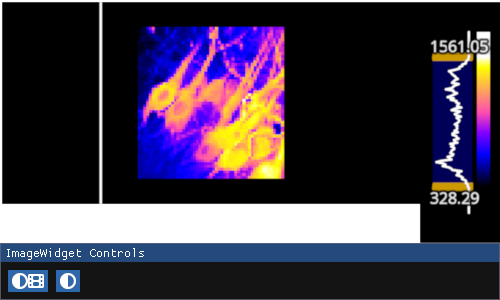

In [11]:
rows, cols = rs.get_selected_indices()
sub = movie[:, rows[0]:rows[-1]:2, cols[0]:cols[-1]:2]
iw_movie = fpl.ImageWidget(sub.std(axis=0), cmap="gnuplot2")
iw_movie.show()

In [12]:
from ipywidgets import IntSlider, VBox

In [13]:
series = sub.reshape(sub.shape[0], sub.shape[1] * sub.shape[2]).T
series.shape

(2915, 10000)

In [14]:
B = series @ series.T

In [15]:
B_plus = B.copy()
B_minus = B.copy()

In [16]:
B_minus[B_minus > 0] = 0
B_minus = np.abs(B_minus)

B_plus[B_plus < 0] = 0

In [17]:
B_minus.min(), B_minus.max()

(np.float32(0.0), np.float32(4443763700.0))

In [18]:
B_plus.min(), B_plus.max()

(np.float32(0.0), np.float32(24368667000.0))

In [23]:
d = 1.0 / np.sum(B_plus.astype(np.float64), axis=0)
a = np.diag(d) @ B_plus

In [24]:
a.sum(axis=1)

array([1., 1., 1., ..., 1., 1., 1.])

In [25]:
import pygpcca as gp

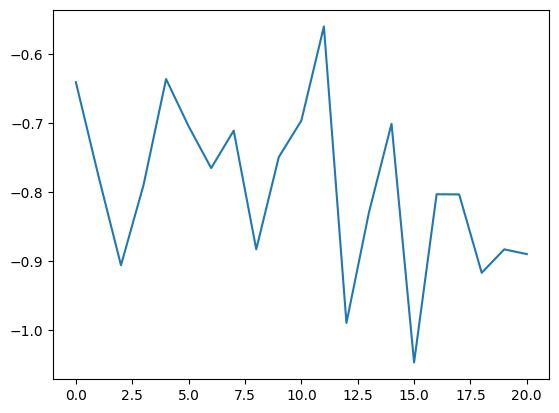

In [26]:
gpcca = gp.GPCCA(a, z="LM", method="brandts")

mc = gpcca.minChi(10, 30)

plt.plot(mc)

In [29]:
mc

[np.float64(-0.6411254039865187),
 np.float64(-0.7767280916284404),
 np.float64(-0.906097372943906),
 np.float64(-0.7900432622982202),
 np.float64(-0.636526335132797),
 np.float64(-0.7049427522132701),
 np.float64(-0.7654854467350058),
 np.float64(-0.7112175670584373),
 np.float64(-0.8830291508652727),
 np.float64(-0.7494780583554932),
 np.float64(-0.6967735185070436),
 np.float64(-0.5604744680982049),
 np.float64(-0.9896038995544808),
 np.float64(-0.8293860621944272),
 np.float64(-0.7012897203689022),
 np.float64(-1.0468062600194423),
 np.float64(-0.8033165427721403),
 np.float64(-0.8035547925733242),
 np.float64(-0.9170566574262574),
 np.float64(-0.88303664922721),
 np.float64(-0.8899504533894762)]

In [30]:
np.argmax(mc)

np.int64(11)

In [31]:
%%time
gpcca.optimize({'m_min':21, 'm_max':22})

CPU times: user 1min 20s, sys: 52.1 ms, total: 1min 20s
Wall time: 1min 20s


GPCCA[n=2915, n_macrostates=21]

In [32]:
labels = gpcca.memberships.reshape(sub.shape[1], sub.shape[2], gpcca.memberships.shape[-1])

In [33]:
fig_comps = fpl.Figure(canvas="glfw")

ix = 0
for i in range(7):
    for j in range(3):
        img = labels.T[ix].T
        fig_comps[0, 0].add_image(img, cmap="viridis", offset=(i * img.shape[1] + 10 * i, j * img.shape[0] + 10 * j, 0))
        ix += 1

iw_movie = fpl.ImageWidget(sub, figure_kwargs={"canvas": "glfw"}, cmap="gnuplot2")


fig_comps.show(), iw_movie.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


(<wgpu.gui.glfw.GlfwWgpuCanvas at 0x7f4758731510>,
 <wgpu.gui.glfw.GlfwWgpuCanvas at 0x7f47350a8510>)

In [34]:
d = 1.0 / np.sum(B_minus.astype(np.float64), axis=0)
a = np.diag(d) @ B_minus

In [35]:
a.sum(axis=1)

array([1., 1., 1., ..., 1., 1., 1.])

In [36]:
import pygpcca as gp

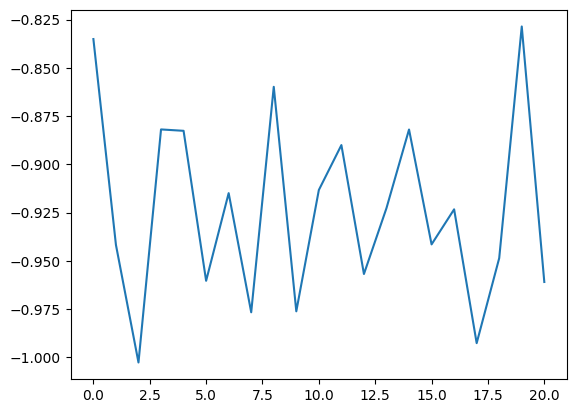

In [37]:
gpcca = gp.GPCCA(a, z="LM", method="brandts")

mc = gpcca.minChi(10, 30)

plt.plot(mc)

In [38]:
mc

[np.float64(-0.8350621612900503),
 np.float64(-0.9417583505627993),
 np.float64(-1.0027282213838458),
 np.float64(-0.8819139287342824),
 np.float64(-0.8826280483133017),
 np.float64(-0.9603862244382921),
 np.float64(-0.9149367913323286),
 np.float64(-0.976708691803408),
 np.float64(-0.8598176917137853),
 np.float64(-0.9762019833031302),
 np.float64(-0.9133121221712555),
 np.float64(-0.8900257444362223),
 np.float64(-0.9568584119515928),
 np.float64(-0.922700802861811),
 np.float64(-0.8819577917817601),
 np.float64(-0.9415096056630741),
 np.float64(-0.9233330824043018),
 np.float64(-0.9927089136560885),
 np.float64(-0.9486338058114558),
 np.float64(-0.8285386853884357),
 np.float64(-0.9609971616361164)]

In [39]:
np.argmax(mc)

np.int64(19)

In [40]:
%%time
gpcca.optimize({'m_min':10, 'm_max':11})

CPU times: user 8.11 s, sys: 46.1 ms, total: 8.16 s
Wall time: 8.16 s


GPCCA[n=2915, n_macrostates=10]

In [41]:
labels = gpcca.memberships.reshape(sub.shape[1], sub.shape[2], gpcca.memberships.shape[-1])

In [44]:
fig_comps = fpl.Figure(canvas="glfw")

ix = 0
for i in range(5):
    for j in range(2):
        img = labels.T[ix].T
        fig_comps[0, 0].add_image(img, cmap="viridis", offset=(i * img.shape[1] + 10 * i, j * img.shape[0] + 10 * j, 0))
        ix += 1

iw_movie = fpl.ImageWidget(sub, figure_kwargs={"canvas": "glfw"}, cmap="gnuplot2")


fig_comps.show(), iw_movie.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


(<wgpu.gui.glfw.GlfwWgpuCanvas at 0x7f47247fdfd0>,
 <wgpu.gui.glfw.GlfwWgpuCanvas at 0x7f4723d959d0>)